In [207]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load
!pip install --no-cache-dir --force-reinstall pyyaml -q
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 807.9/807.9 kB 3.8 MB/s eta 0:00:0000:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.29.0 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
/kaggle/input/datasets/shadman1028/cicids2017-official-flow-feature-csv-files/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
/kaggle/input/datasets/shadman1028/cicids2017-official-flow-feature-csv-files/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
/kaggle/input/datasets/shadman1028/cicids2017-official-flow-feature-csv-files/Friday-WorkingHours-Morning.pcap_ISCX.csv
/kaggle/input/datasets/shadman1028/cicids2017-official-flow-feature-csv-files/Monday-WorkingHours.pcap_ISCX.csv
/kaggle/input/datasets/shadman1028/cicids2017-official-flow-feature-csv-files/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
/kaggle/input/data

In [208]:
df_wed = pd.read_csv('/kaggle/input/datasets/shadman1028/cicids2017-official-flow-feature-csv-files/Wednesday-workingHours.pcap_ISCX.csv')

In [209]:
df_wed.head()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,80,38308,1,1,6,6,6,6,6.000000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,389,479,11,5,172,326,79,0,15.636364,31.449238,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,88,1095,10,6,3150,3150,1575,0,315.000000,632.561635,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,389,15206,17,12,3452,6660,1313,0,203.058823,425.778474,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,88,1092,9,6,3150,3152,1575,0,350.000000,694.509719,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [210]:
df_wed.describe()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,692703.000000,6.927030e+05,692703.000000,692703.000000,6.927030e+05,6.927030e+05,692703.000000,692703.000000,692703.000000,692703.000000,...,692703.000000,692703.000000,6.927030e+05,6.927030e+05,6.927030e+05,6.927030e+05,6.927030e+05,6.927030e+05,6.927030e+05,6.927030e+05
mean,5686.869462,2.800168e+07,9.556261,10.214079,5.550930e+02,1.699644e+04,233.593936,15.022183,60.555440,82.895863,...,6.121279,26.761141,9.224478e+04,4.760852e+04,1.627363e+05,6.315186e+04,2.211122e+07,4.743744e+05,2.252174e+07,2.173373e+07
std,15727.423560,4.276680e+07,747.197814,984.204633,6.163663e+03,2.241175e+06,603.751856,51.068835,157.643794,226.126084,...,715.155068,6.322368,7.007049e+05,4.742081e+05,1.094616e+06,6.051023e+05,3.812415e+07,4.488512e+06,3.848292e+07,3.807725e+07
min,0.000000,-1.000000e+00,1.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,...,0.000000,-1.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,53.000000,2.010000e+02,2.000000,1.000000,1.200000e+01,0.000000e+00,6.000000,0.000000,6.000000,0.000000,...,0.000000,20.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,80.000000,6.143700e+04,2.000000,2.000000,8.200000e+01,1.880000e+02,46.000000,0.000000,41.000000,0.000000,...,1.000000,32.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,443.000000,8.302437e+07,7.000000,6.000000,3.650000e+02,1.159500e+04,341.000000,32.000000,56.666667,128.916917,...,2.000000,32.000000,9.910000e+02,0.000000e+00,9.910000e+02,9.880000e+02,1.590000e+07,0.000000e+00,1.650000e+07,1.000000e+07
max,65487.000000,1.200000e+08,203943.000000,272353.000000,1.224076e+06,6.270000e+08,24820.000000,2065.000000,4640.757576,6429.190773,...,197124.000000,60.000000,1.000000e+08,7.420000e+07,1.050000e+08,1.000000e+08,1.200000e+08,7.690000e+07,1.200000e+08,1.200000e+08


In [211]:
df_wed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 692703 entries, 0 to 692702
Data columns (total 79 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0    Destination Port             692703 non-null  int64  
 1    Flow Duration                692703 non-null  int64  
 2    Total Fwd Packets            692703 non-null  int64  
 3    Total Backward Packets       692703 non-null  int64  
 4   Total Length of Fwd Packets   692703 non-null  int64  
 5    Total Length of Bwd Packets  692703 non-null  int64  
 6    Fwd Packet Length Max        692703 non-null  int64  
 7    Fwd Packet Length Min        692703 non-null  int64  
 8    Fwd Packet Length Mean       692703 non-null  float64
 9    Fwd Packet Length Std        692703 non-null  float64
 10  Bwd Packet Length Max         692703 non-null  int64  
 11   Bwd Packet Length Min        692703 non-null  int64  
 12   Bwd Packet Length Mean       692703 non-nul

In [212]:
df_wed.isnull().sum()

 Destination Port              0
 Flow Duration                 0
 Total Fwd Packets             0
 Total Backward Packets        0
Total Length of Fwd Packets    0
                              ..
Idle Mean                      0
 Idle Std                      0
 Idle Max                      0
 Idle Min                      0
 Label                         0
Length: 79, dtype: int64

**lets fix all columns names with space in between**

In [213]:
df_wed.columns = df_wed.columns.str.strip()

**lets check for infinite values.**

Infinite values usually happen when there is a division.
in this dataset we can see that some column values where gotten from division from values from other columns

In [214]:
print(df_wed.isin([np.inf, -np.inf]).sum().sum())

1586


In [215]:
df_wed.replace([np.inf, -np.inf], np.nan, inplace=True)

**EDA**

lets check the label distribution

In [216]:
df_wed['Label'].value_counts()

Label
BENIGN              440031
DoS Hulk            231073
DoS GoldenEye        10293
DoS slowloris         5796
DoS Slowhttptest      5499
Heartbleed              11
Name: count, dtype: int64

In [217]:
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
%matplotlib inline

fig = px.bar(df_wed['Label'].value_counts().reset_index(),
             x='Label',
             y='count',
             title='Label Distribution')
fig.show()

Here we can see that **BENIGN** and **Dos Hulk** have a higher distribution than other values 

In [218]:
fig = px.box(df_wed,
            x='Label',
            y='Flow Duration',
            title='Label vs Flow Distribution')
fig.show()

next lets check for duplicate rows 

In [219]:
print(df_wed.duplicated().sum())

81909


This means that 81909 rows have exact duplicates of other rows.This happens because 
-DDos attacks repeat the exact same connection thousands of time 
-CICFlowMeter sometimes repeat the exact same exact same flow twice

We should remove this because : it biasis the model , if a duplicate ends up in bost training and test data , our model have already seen this wwhich may cause a bias


In [220]:
df_wed = df_wed.drop_duplicates()
print(df_wed.shape)

(610794, 79)


we went from 692703 to 610794 after removing duplicates


now lets see which features are more correlated with the other

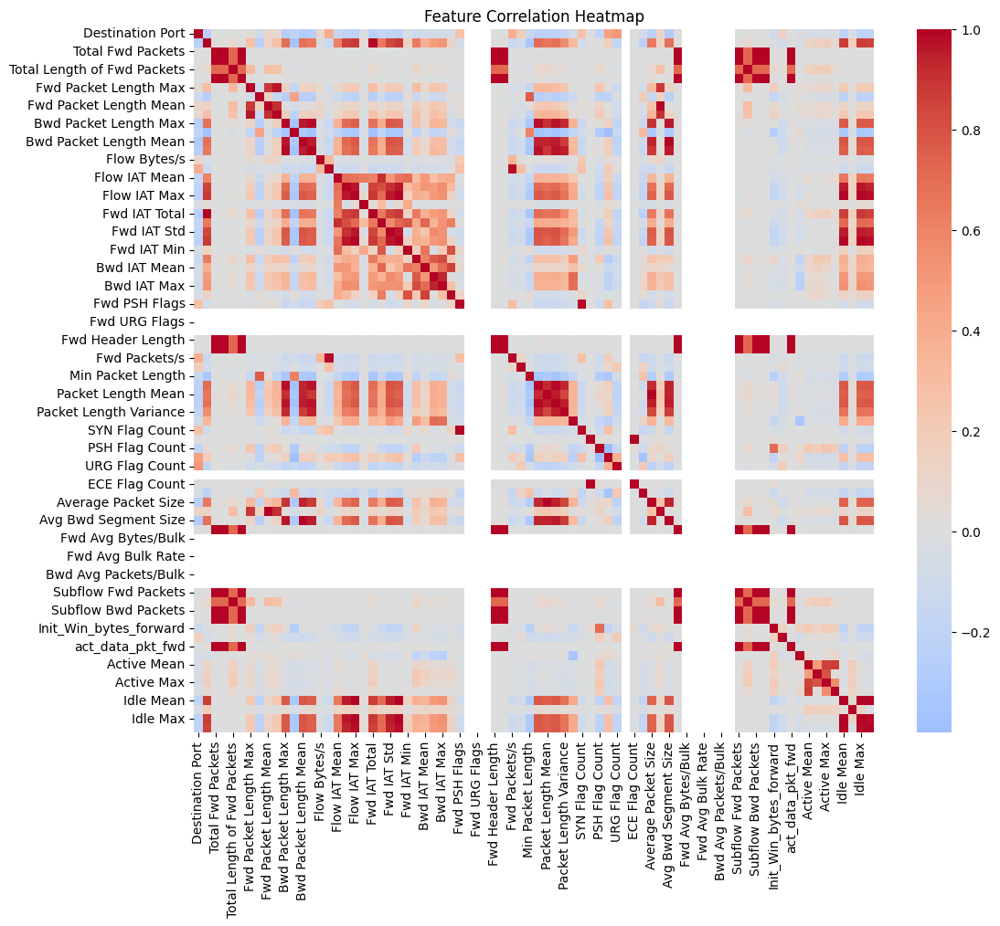

In [221]:
corr = df_wed.drop(columns='Label').corr()
plt.figure(figsize=(12,10))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Feature Correlation Heatmap')
plt.show()

Here we see that we have highly correlated features, this is redudant so going foward we are going to drop some redundant feature 

**PREPROCESSING**

In [222]:
constant_cols = df_wed.columns[df_wed.nunique() == 1].tolist()
print(constant_cols)

['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


Lets drop all these columns 

In [223]:
df_wed= df_wed.drop(columns =constant_cols)

lets check for columns containing negative values 

In [224]:
numeric_cols= df_wed.drop(columns='Label')
negative_cols = (numeric_cols<0).any()
negative_cols[negative_cols]

Flow Duration              True
Flow Bytes/s               True
Flow Packets/s             True
Flow IAT Mean              True
Flow IAT Max               True
Flow IAT Min               True
Fwd IAT Min                True
Fwd Header Length          True
Fwd Header Length.1        True
Init_Win_bytes_forward     True
Init_Win_bytes_backward    True
min_seg_size_forward       True
dtype: bool

these are all the columns containing negative values we can either replace the negative values with NaN or drop them completely 

i decided to drop these columns completely beacuse -1 in this dataset is a bug and dropping those rows is cleaner 

In [225]:
df_wed[(df_wed[negative_cols.index[negative_cols]]>=0).all(axis=1)]

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,80,38308,1,1,6,6,6,6,6.000000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,389,479,11,5,172,326,79,0,15.636364,31.449238,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,88,1095,10,6,3150,3150,1575,0,315.000000,632.561635,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,389,15206,17,12,3452,6660,1313,0,203.058823,425.778474,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,88,1092,9,6,3150,3152,1575,0,350.000000,694.509719,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
692690,443,392,3,1,18,6,6,6,6.000000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
692694,35450,33,1,1,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
692696,80,11512230,5,5,672,3525,672,0,134.400000,300.527536,...,32,821.0,0.0,821,821,6506213.0,0.0,6506213,6506213,DoS GoldenEye
692697,49346,145,1,1,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


Let's encode the label column into numbers since skitlearn can't work with text

In [226]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df_wed['Label'] = le.fit_transform(df_wed['Label'])
print(df_wed['Label'].value_counts())
print(le.classes_)

Label
0    417035
2    172849
1     10286
4      5385
3      5228
5        11
Name: count, dtype: int64
['BENIGN' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest' 'DoS slowloris'
 'Heartbleed']


Split features and target


In [227]:
X = df_wed.drop(columns='Label')
y = df_wed['Label']

train/test split:

In [228]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(488635, 68) (122159, 68)


Scaling features

In [229]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

**MODELLING**

Training the model 

In [230]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [231]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = rf.predict(X_test)

print(classification_report(y_pred, y_test, target_names=le.classes_))

                  precision    recall  f1-score   support

          BENIGN       1.00      1.00      1.00     83467
   DoS GoldenEye       1.00      1.00      1.00      2017
        DoS Hulk       1.00      1.00      1.00     34585
DoS Slowhttptest       0.99      1.00      0.99      1003
   DoS slowloris       1.00      0.99      0.99      1084
      Heartbleed       1.00      1.00      1.00         3

        accuracy                           1.00    122159
       macro avg       1.00      1.00      1.00    122159
    weighted avg       1.00      1.00      1.00    122159



In [232]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = rf.predict(X_test)

print(classification_report(y_pred, y_test, target_names=le.classes_))

                  precision    recall  f1-score   support

          BENIGN       1.00      1.00      1.00     83467
   DoS GoldenEye       1.00      1.00      1.00      2017
        DoS Hulk       1.00      1.00      1.00     34585
DoS Slowhttptest       0.99      1.00      0.99      1003
   DoS slowloris       1.00      0.99      0.99      1084
      Heartbleed       1.00      1.00      1.00         3

        accuracy                           1.00    122159
       macro avg       1.00      1.00      1.00    122159
    weighted avg       1.00      1.00      1.00    122159



Essentially 100% on everything — including Heartbleed which only had 3 samples in test data.

Here is why 

CICIDS2017 is a lab-generated dataset. Attack traffic was artificially created in a controlled environment, so attack patterns are very clean and distinct. Random Forest can pick up on that almost perfectly.
In real-world network traffic:

Attacks blend in with normal traffic
Patterns are noisier
100% accuracy would never happen

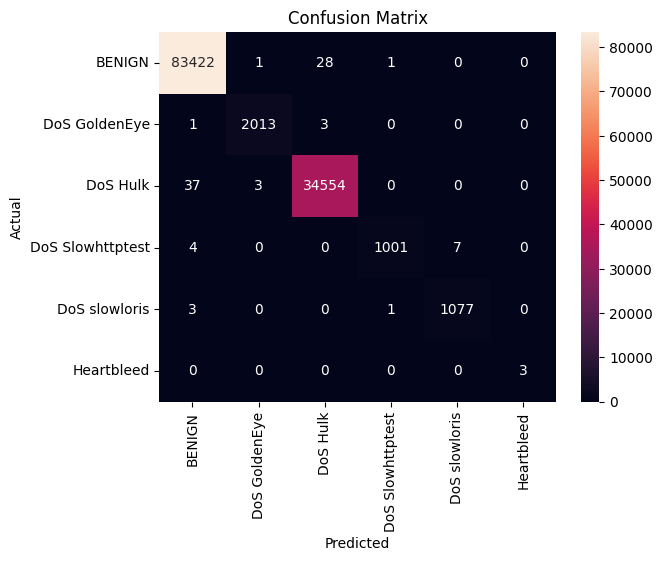

In [233]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

**Results**

BENIGN ; 29 misclassifiedout of 83,422 — tiny
DoS GoldenEye4 misclassifiedout of 2,013 — tiny
DoS Hulk40 misclassifiedout of 34,554 — tiny
DoS Slowhttptest11 misclassifiedout of 1,001
DoS slowloris4 misclassifiedout of 1,077
Heartbleed0 misclassifiedperfect — all 3 caught 

Most mistakes are between similar attack types — for example DoS Slowhttptest and DoS slowloris confusing each other. That makes sense because they're both slow HTTP attacks with similar traffic patterns.

**FEATURE IMPORTANCE**

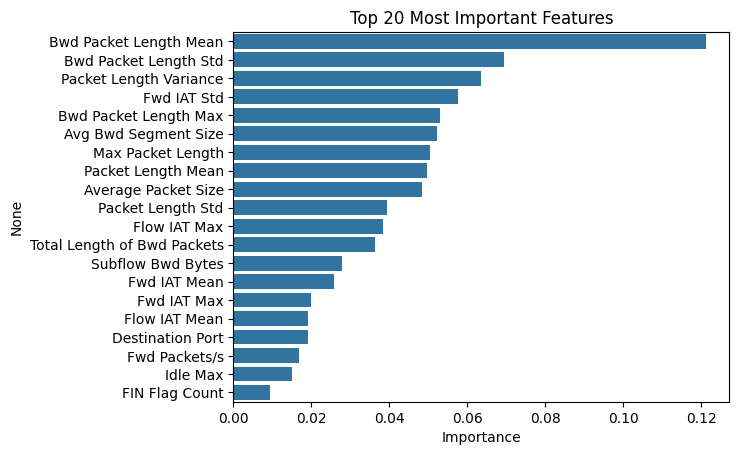

In [234]:
import pandas as pd

feature_names = df_wed.drop(columns='Label').columns

importances = pd.Series(rf.feature_importances_, index=feature_names)
top20 = importances.sort_values(ascending=False).head(20)

sns.barplot(x=top20.values, y=top20.index)
plt.title('Top 20 Most Important Features')
plt.xlabel('Importance')
plt.show()

*Feature importance analysis revealed that backward packet length statistics were the strongest indicators of DoS attacks, which aligns with how these attacks generate abnormal server-side traffic patterns*

lets save the model 

In [235]:
import joblib

joblib.dump(rf, 'random_forest_nids.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(le, 'label_encoder.pkl')

['label_encoder.pkl']

In [236]:
import os
os.listdir('/kaggle/working/')

['scaler.pkl',
 'sample_traffic.csv',
 'random_forest_nids.pkl',
 'label_encoder.pkl',
 '.virtual_documents']

In [237]:
print(X_train.shape)

(488635, 68)


In [238]:
feature_names = df_wed.drop(columns='Label').columns.tolist()
print(feature_names)

['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'ECE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 'Avg Fwd Segment Size', 'A

In [240]:
sample = df_wed.drop(columns='Label').head(100)
sample.to_csv('sample_traffic.csv', index=False)